# Frequências dos estudos e das gravações — 03/10/2026

## O que os trabalhos realmente descrevem

- Mukundarajan et al., eLife 2017, DOI 10.7554/eLife.27854: faixa geral de 200–700 Hz, distribuições instantâneas em janelas de 20 ms, variações dentro de um mesmo voo e sobreposição entre espécies. Isso não é uma faixa exclusiva de Aedes. Métodos p.22: populações em gaiolas, acompanhando mosquitos individuais com o telefone; não equivale automaticamente a gravar um enxame inteiro sem isolamento. P.8 discute variação entre populações e a conveniência de referências locais.
- Altayeb et al., TinyML 2022, p.133 e Figura 2 p.134: componentes principais entre 500 e 700 Hz em Aedes aegypti e albopictus; portanto a própria faixa não distingue essas duas espécies. Reamostragem a 16 kHz não significa batimento das asas a 16 kHz.
- Mosquito wingbeat analysis and classification using deep learning, EUSIPCO 2018, p.2411, Figura 2: exemplo de Aedes perto de 550 Hz e harmônicos. É sinal de sensor óptico, não gravação de pressão sonora por microfone. Energia abaixo de 100 Hz nesse sensor é interpretada como passagem/movimento do corpo; não transferimos essa explicação automaticamente ao Arduino.

## Método desta comparação

74 arquivos: amostra determinística de até 12 grupos por classe/fonte, quatro Aedes e oito negativos CDMSC D3, e o Drive. Havendo vários arquivos no grupo, foi escolhido o primeiro por caminho. Assim, a amostra não representa todos os indivíduos ou a distribuição completa de cada base. Foram usados rótulos existentes; espécie não foi inferida pelo espectro.

Decodificação sem normalizar amplitude, canais promediados e reamostragem correta a 16 kHz. Welch com Hann, 4096 amostras e 2048 de sobreposição: espaçamento de 3,90625 Hz. Janelas reais de 0,992 s ou 0,3 s, até 120 distribuídas uniformemente por arquivo; sem repetir ou preencher áudio. Qualidade segue o critério anterior de amplitude mínima e saturação. Cada arquivo tem peso igual nas estatísticas entre fontes; as janelas não são tratadas como indivíduos independentes.

A tabela mostra a mediana entre arquivos do pico mais forte na busca de 200–900 Hz. Esse pico é uma característica espectral, **não uma estimativa validada da fundamental das asas**. Ruído e harmônicos podem vencer essa busca. A faixa ampliada a 900 Hz evita impor que todos os sinais obedeçam a 500–700 Hz.

| source       |   label |   files |   peak_median_hz |   peak_q25 |   peak_q75 |   band_share |   study_share |
|:-------------|--------:|--------:|-----------------:|-----------:|-----------:|-------------:|--------------:|
| CDMSC_D3     |       0 |       8 |          638.672 |    598.633 |    781.250 |        0.285 |         0.412 |
| CDMSC_D3     |       1 |       4 |          730.469 |    496.094 |    872.070 |        0.244 |         0.294 |
| Drive        |       1 |       1 |          589.844 |    589.844 |    589.844 |        0.085 |         0.459 |
| dryad        |       0 |      12 |          425.781 |    229.492 |    624.023 |        0.405 |         0.186 |
| dryad        |       1 |      12 |          558.594 |    376.953 |    578.125 |        0.510 |         0.557 |
| humbug       |       0 |      12 |          462.891 |    337.891 |    745.117 |        0.068 |         0.184 |
| humbug       |       1 |      12 |          521.484 |    406.250 |    579.102 |        0.013 |         0.243 |
| mosquitosong |       0 |       6 |          333.984 |    211.914 |    564.453 |        0.090 |         0.144 |
| mosquitosong |       1 |       4 |          652.344 |    540.039 |    782.227 |        0.041 |         0.183 |
| ufrgs        |       0 |       1 |          609.375 |    609.375 |    609.375 |        0.581 |         0.736 |
| ufrgs        |       1 |       2 |          654.297 |    645.508 |    663.086 |        0.216 |         0.396 |

band_share é a mediana por arquivo da fração de energia 200–900 Hz em relação a 20–7500 Hz. study_share é a fração 500–700 Hz dentro de 200–900 Hz. Valores são frações, não SNR nem probabilidade da espécie.

## Drive

106,24 s, taxa original declarada de 16000 amostras/s, 107 janelas, 105 válidas. Pico da PSD média entre 200–900 Hz: 589,84 Hz; mediana dos picos nas janelas válidas: 578,13 Hz. Picos adicionais: aproximadamente 602, 621, 648 e 1250 Hz. Múltiplos próximos podem refletir diferentes mosquitos, modulação e ruído; não há uma fundamental única confirmada. O pico 1250 Hz não é exatamente o dobro de 590 Hz, logo não afirmamos uma série harmônica simples a partir desses picos.

Na PSD calculada para o arquivo inteiro, a energia entre 20–7500 Hz distribui-se aproximadamente assim: 20–200 Hz, 71,69%; 200–900 Hz, 11,62%; 900–3000 Hz, 13,98%; 3000–7500 Hz, 2,72%. O pico mais forte em toda essa faixa está em 23,44 Hz. Esta média energética do arquivo inteiro difere da mediana por janela da tabela: eventos fortes recebem mais peso na primeira. Os números não incluem DC ou energia abaixo de 20 Hz.

O Drive contém frequências compatíveis com as descritas no TinyML. A falha do classificador não pode ser atribuída apenas a um batimento fora da faixa. A presença de energia baixa e a forma do espectro diferem das referências; isso pode afetar características do modelo, mas esta análise não demonstra causalidade.

Não sabemos quanto das baixas frequências vem do voo, manuseio, ambiente, eletrônica ou da caixa. Reverberação pode mudar amplitudes e sobreposições; não demonstramos deslocamento sistemático da frequência por vidro. A taxa gravada no cabeçalho também não verifica a precisão do relógio: seria preciso registrar um tom de frequência conhecida no mesmo sistema.

## Interpretação e próximos testes

As medianas positivas variam de aproximadamente 521 Hz (HumBug) a 730 Hz (quatro arquivos CDMSC). As faixas dos negativos se sobrepõem; por exemplo, os negativos CDMSC têm mediana perto de 639 Hz. Isso impede identificar Aedes simplesmente procurando energia em 500–700 Hz.

Para distinguir contribuição biológica e instrumental: gravar caixa vazia, tom conhecido, Aedes confirmado e espécies negativas no mesmo Arduino, distância e temperatura registrados. Comparar espectro bruto, rastreamento de várias linhas e harmônicos e versão filtrada, com filtros escolhidos na validação e os mesmos filtros no treino e no teste. Aplicar apenas um filtro ao Drive e escolher o que faz o modelo acertar seria ajustar ao teste. Esta rodada é descritiva: nenhum modelo foi retreinado e nenhum código do Arduino foi alterado.

![Espectros relativos de Aedes](reports/assets/frequency_aedes_sources.png)

![Trechos iniciais fixos, até cinco segundos, sem selecionar pelo resultado](reports/assets/frequency_spectrograms.png)

O espectrograma mostra o primeiro trecho de um arquivo fixo por fonte, não o melhor exemplo nem todo o arquivo. O Drive começa com trecho quase silencioso; a análise numérica cobre todas as suas janelas.

## Referências

Os três PDFs fornecidos foram lidos e as figuras pertinentes renderizadas e inspecionadas. Fontes: eLife https://doi.org/10.7554/eLife.27854; TinyML e EUSIPCO são os PDFs anexados. Artigo online eLife apresentou bloqueio JavaScript, portanto os detalhes foram conferidos no PDF local. Valores extraídos de texto explícito, sem inventar medianas numéricas a partir de figuras.


In [1]:
from pathlib import Path
import pandas as pd
p=Path('results/frequency_comparison_2026_10_03')
s=pd.read_csv(p/'summary.csv')
f=pd.read_csv(p/'files.csv')
display(s)
display(f[f.source.eq('Drive')])
assert len(f)==74
assert f[f.source.eq('Drive')].valid_windows.iloc[0]==105

,source,label,files,peak_median_hz,peak_q25,peak_q75,band_share,study_share
0,CDMSC_D3,0,8,638.671875,598.632812,781.250000,0.284603,0.411986
1,CDMSC_D3,1,4,730.468750,496.093750,872.070312,0.244441,0.294134
2,Drive,1,1,589.843750,589.843750,589.843750,0.084969,0.459489
3,dryad,0,12,425.781250,229.492188,624.023438,0.404910,0.185941
4,dryad,1,12,558.593750,376.953125,578.125000,0.510240,0.556998
5,humbug,0,12,462.890625,337.890625,745.117188,0.067681,0.184046
6,humbug,1,12,521.484375,406.250000,579.101562,0.013498,0.243068
7,mosquitosong,0,6,333.984375,211.914062,564.453125,0.090088,0.143868
8,mosquitosong,1,4,652.343750,540.039062,782.226562,0.040602,0.183426
9,ufrgs,0,1,609.375000,609.375000,609.375000,0.581500,0.735875


,path,source,label,group,sha256,original_sr,seconds,analyzed_windows,valid_windows,peak_200_900,peak_20_7500,peak_window_median,share_200_900,share_500_700_within_band,strong_peaks_hz
73,tmp/private-audio-test/download.audio,Drive,1,Drive,138fce9b9780f22013011849d793938282695a06647eb3...,16000,106.24,107,105,589.84375,23.4375,578.125,0.084969,0.459489,"[589.8, 601.6, 621.1, 648.4, 570.3, 554.7, 546..."


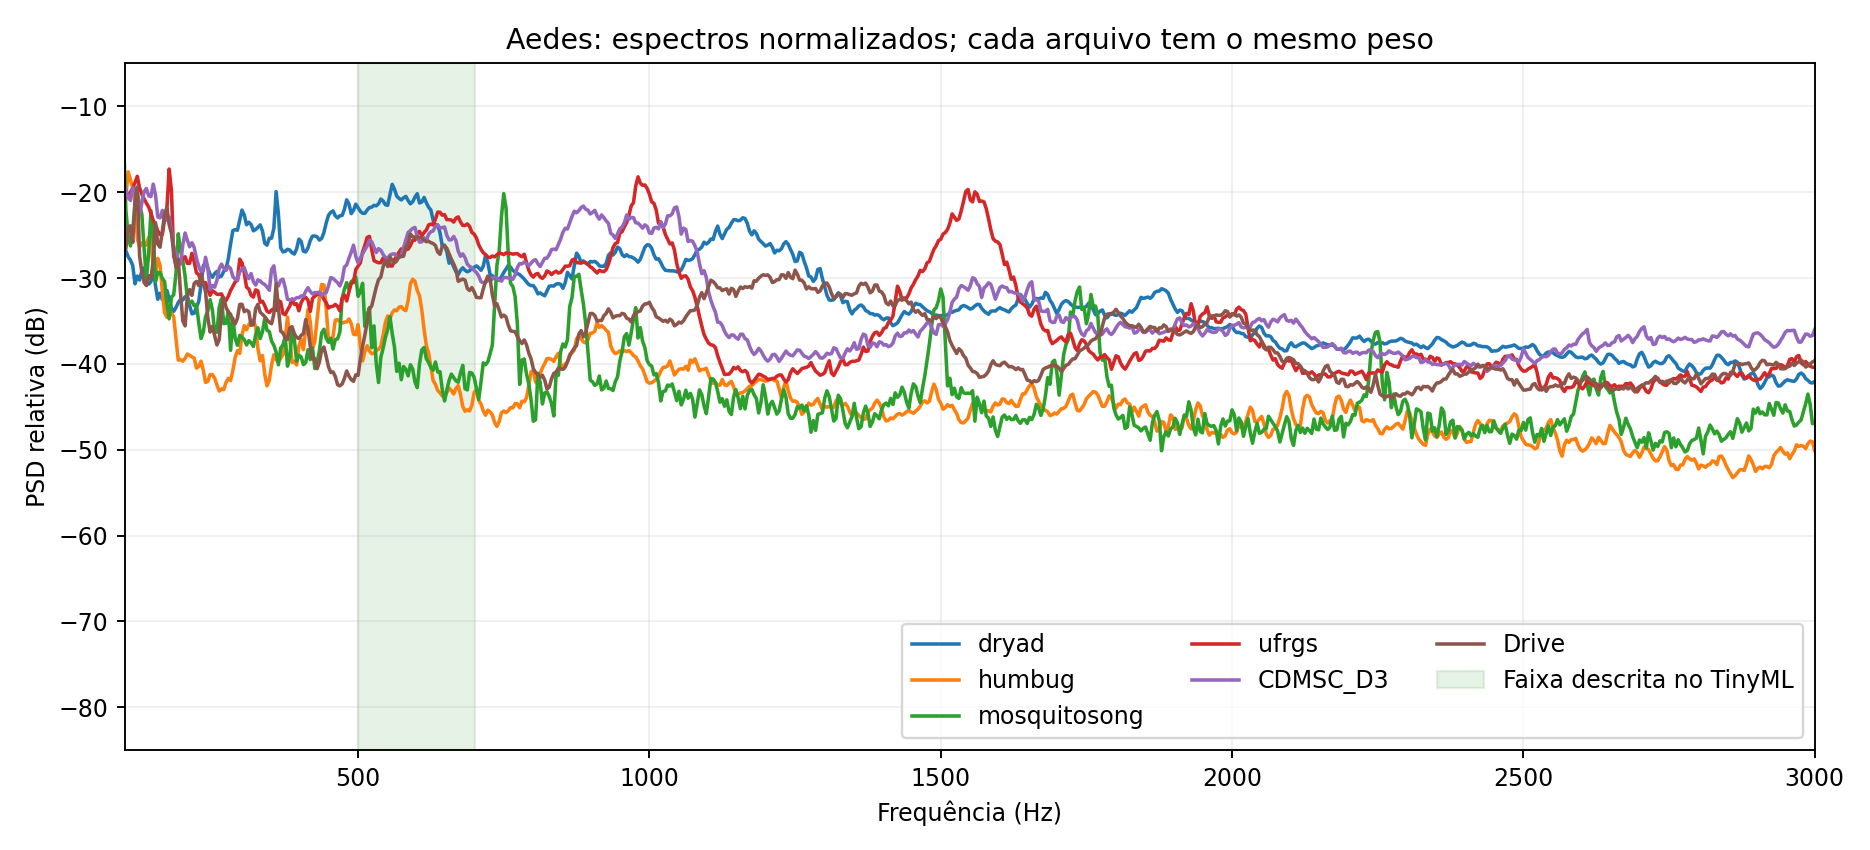

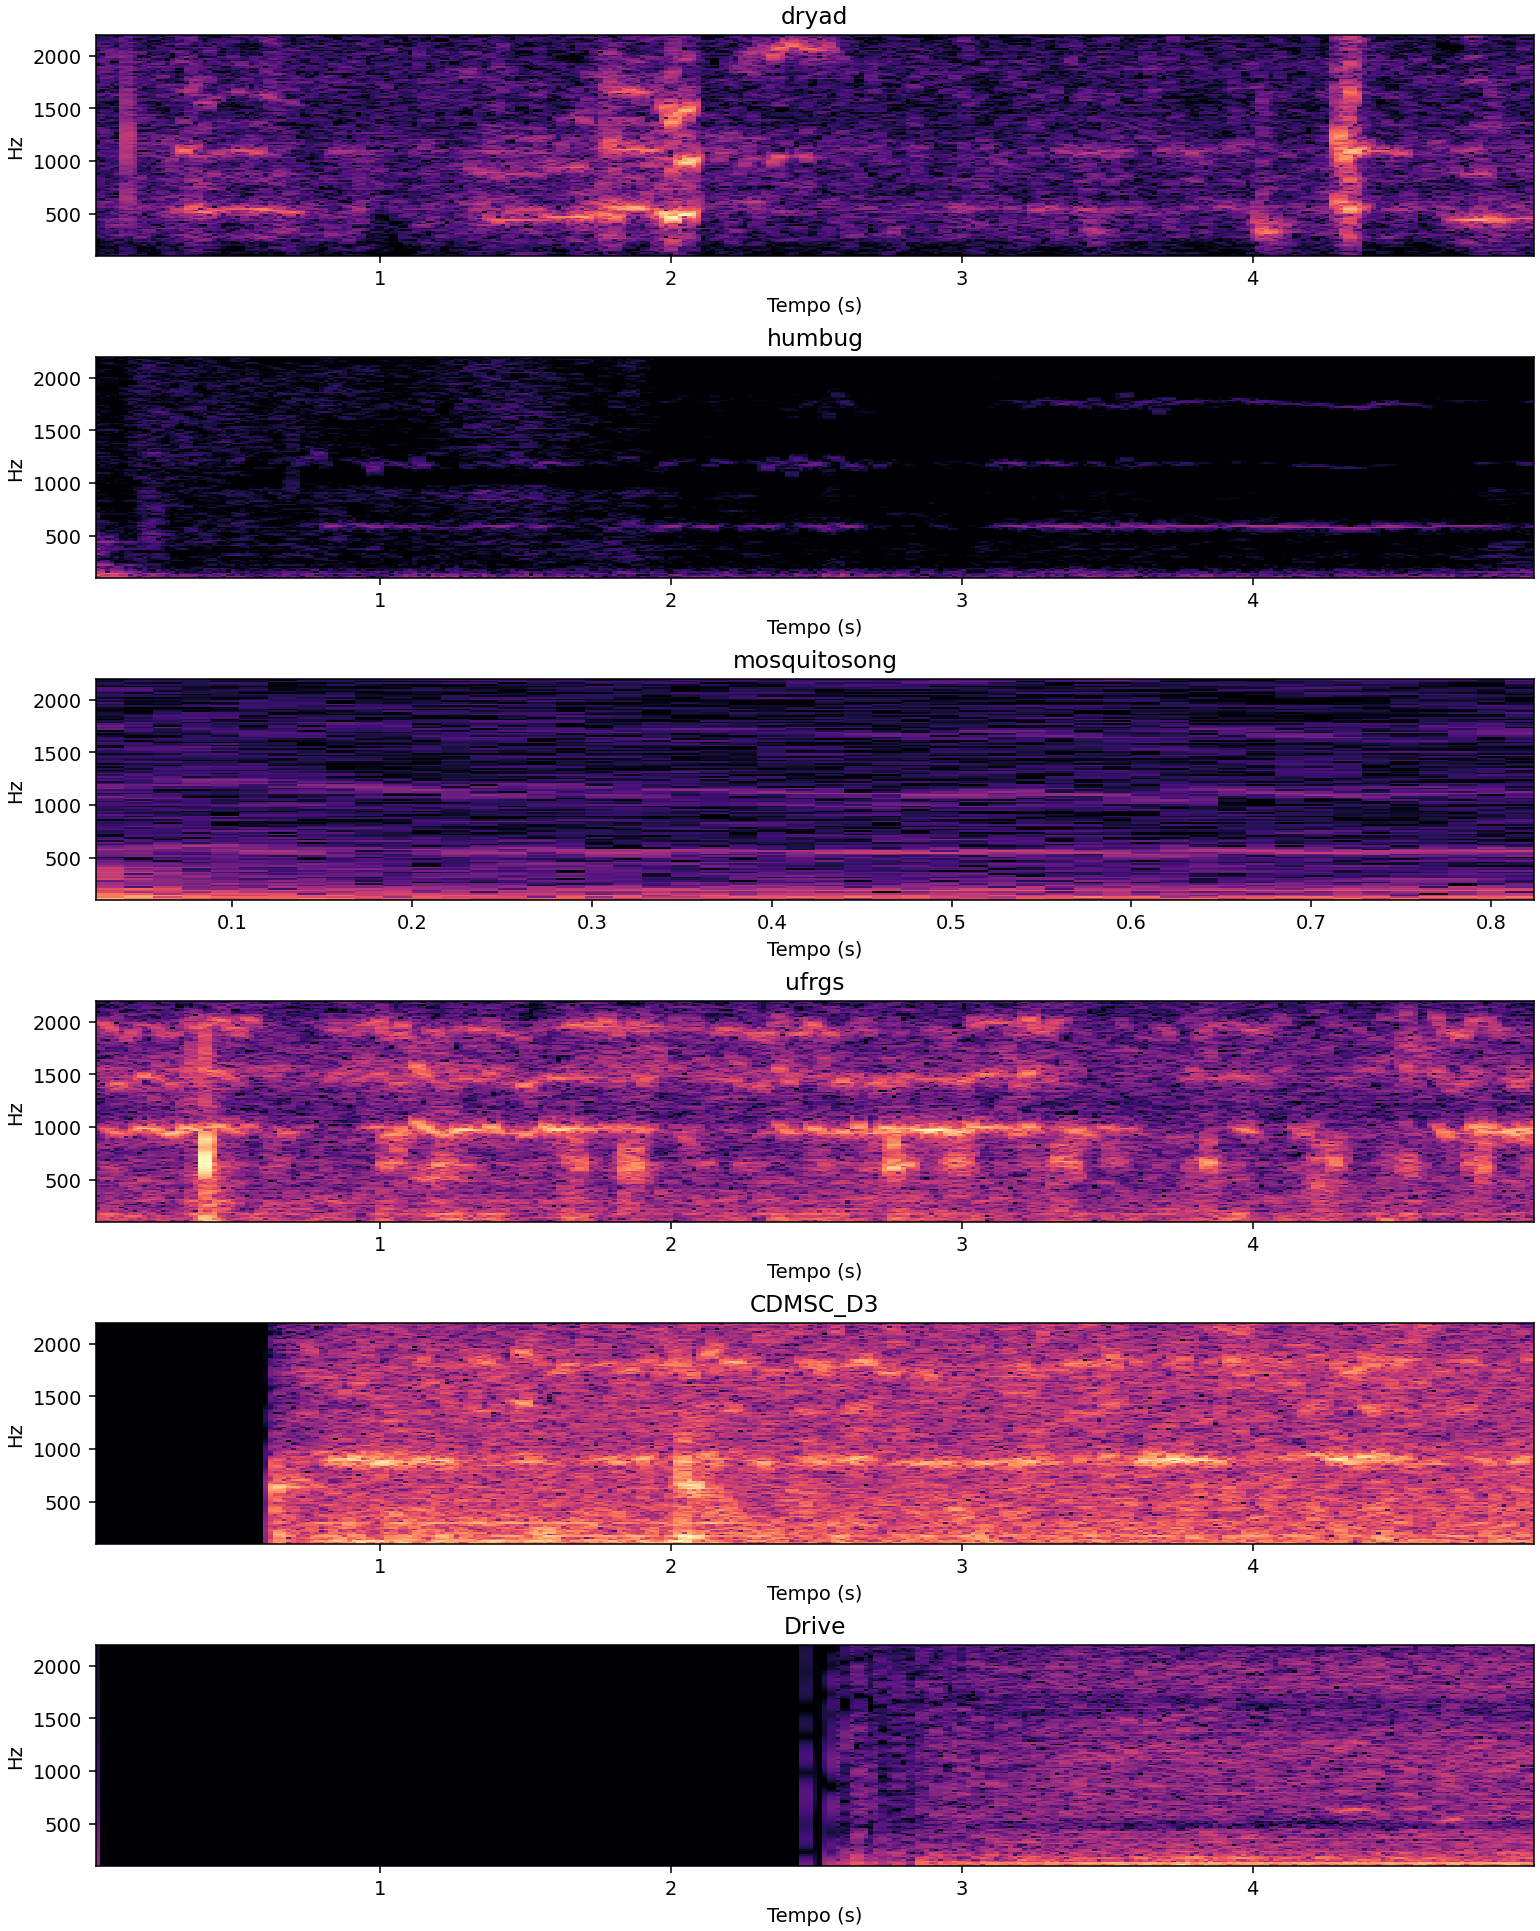

In [2]:
from IPython.display import Image, display
display(Image('reports/assets/frequency_aedes_sources.png'))
display(Image('reports/assets/frequency_spectrograms.png'))